# TSM-CAM · QAOA with CVaR vs. Held–Karp

Both solvers optimize the same Cambodian locations and Haversine distance matrix. QAOA selects the most frequently measured assignment. Held–Karp finds the exact minimum and provides a baseline for measuring QAOA's solution quality.

Run all cells to regenerate both results and measure their local compute times.

In [14]:
%pip install numpy matplotlib networkx qiskit qiskit-aer qiskit-algorithms qiskit-optimization pylatexenc ipykernel


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
from pathlib import Path
from time import perf_counter
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# When saved in tsm-cam, the current directory or its parent is detected.
# Change PROJECT_ROOT manually if your project is somewhere else.
search_roots = [Path.cwd(), *Path.cwd().parents,
                Path('/Users/nak/CADT/projects/tsm-cam')]
PROJECT_ROOT = next((p for p in search_roots
                     if (p / 'app/quantum/qaoa.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Set PROJECT_ROOT to your tsm-cam directory.')
sys.path.insert(0, str(PROJECT_ROOT))

# Optional packages installed locally for this notebook can also be used by the kernel.
notebook_dependencies = PROJECT_ROOT / '.notebook-deps'
if notebook_dependencies.is_dir() and str(notebook_dependencies) not in sys.path:
    sys.path.append(str(notebook_dependencies))

from app.classical.locations import build_straight_distance_matrix


plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
NAVY, TEAL, PURPLE = '#08134d', '#008c95', '#8046e8'
print('Project:', PROJECT_ROOT)


Project: /Users/nak/CADT/projects/tsm-cam


## 1. Read locations and resolve coordinates

Load the departure and destinations with their coordinates. Nodes represent cities; connections are straight lines.

0: Phnom Penh: lat=11.57, lon=104.92
1: Takeo: lat=10.99, lon=104.78
2: Kampong Cham: lat=11.99, lon=105.46
3: Siem Reap: lat=13.36, lon=103.86


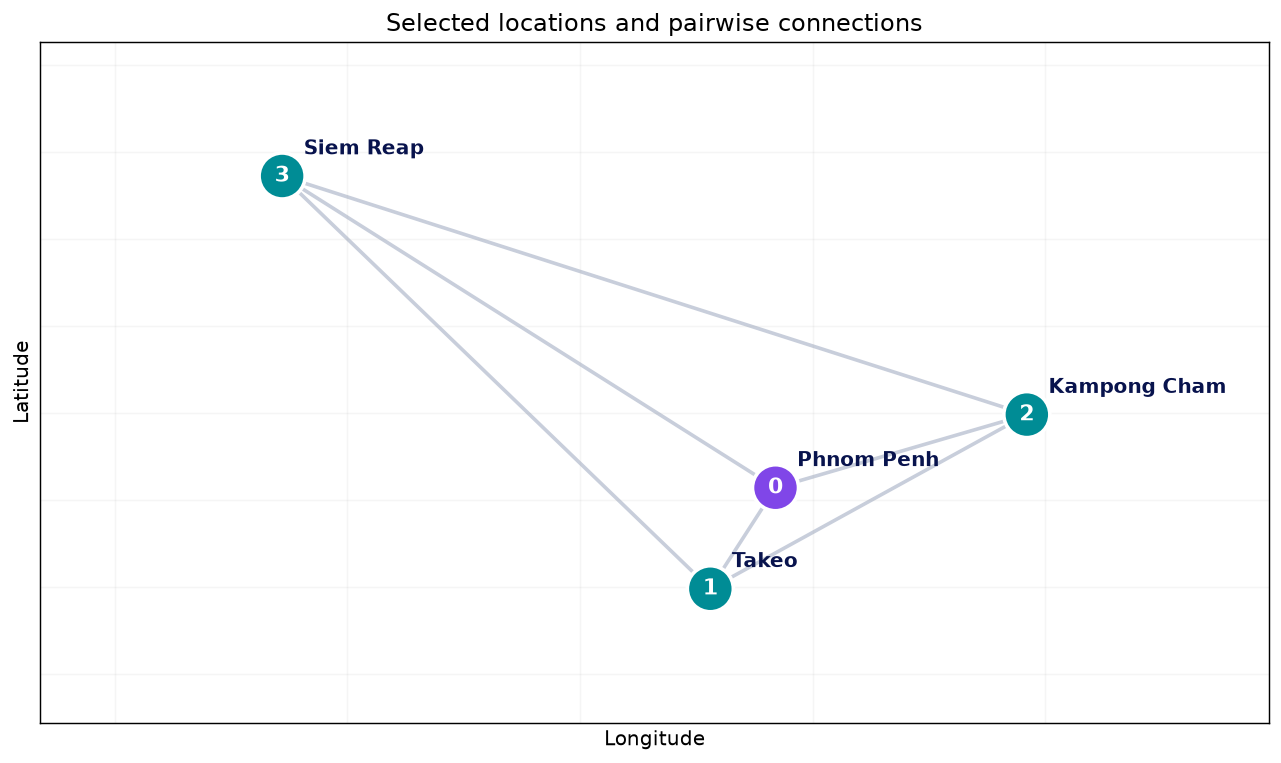

In [16]:
CITY_NAMES = ['Phnom Penh', 'Takeo', 'Kampong Cham', 'Siem Reap']
province_pins = json.loads((PROJECT_ROOT / 'static/data/provinces.json').read_text())
by_name = {p['name'].casefold(): p for p in province_pins}
assert 2 <= len(CITY_NAMES) <= 4, 'Select departure plus 1–3 destinations.'
assert len(set(n.casefold() for n in CITY_NAMES)) == len(CITY_NAMES)
locations = [dict(by_name[name.casefold()]) for name in CITY_NAMES]
n = len(locations)
for i, location in enumerate(locations):
    print(f"{i}: {location['name']}: lat={location['latitude']}, lon={location['longitude']}")

positions = {i: (p['longitude'], p['latitude']) for i, p in enumerate(locations)}
node_colors = [PURPLE if i == 0 else TEAL for i in range(n)]
fig, ax = plt.subplots(figsize=(10, 6))
graph = nx.complete_graph(n)
nx.draw_networkx_edges(graph, positions, ax=ax, edge_color='#c8cedb', width=2)
nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=node_colors,
                       node_size=650, edgecolors='white', linewidths=2)
nx.draw_networkx_labels(graph, positions, labels={i: str(i) for i in range(n)},
                        ax=ax, font_color='white', font_weight='bold')
for i, (lon, lat) in positions.items():
    ax.annotate(locations[i]['name'], (lon, lat), xytext=(12, 12),
                textcoords='offset points', color=NAVY, fontweight='bold')
ax.set(xlabel='Longitude', ylabel='Latitude',
       title='Selected locations and pairwise connections')
ax.margins(0.25)
ax.grid(alpha=0.12)
plt.tight_layout()
plt.show()


## 2. Calculate distances and build the matrix

Calculate pairwise Haversine distances. Each matrix entry is a distance in kilometers.

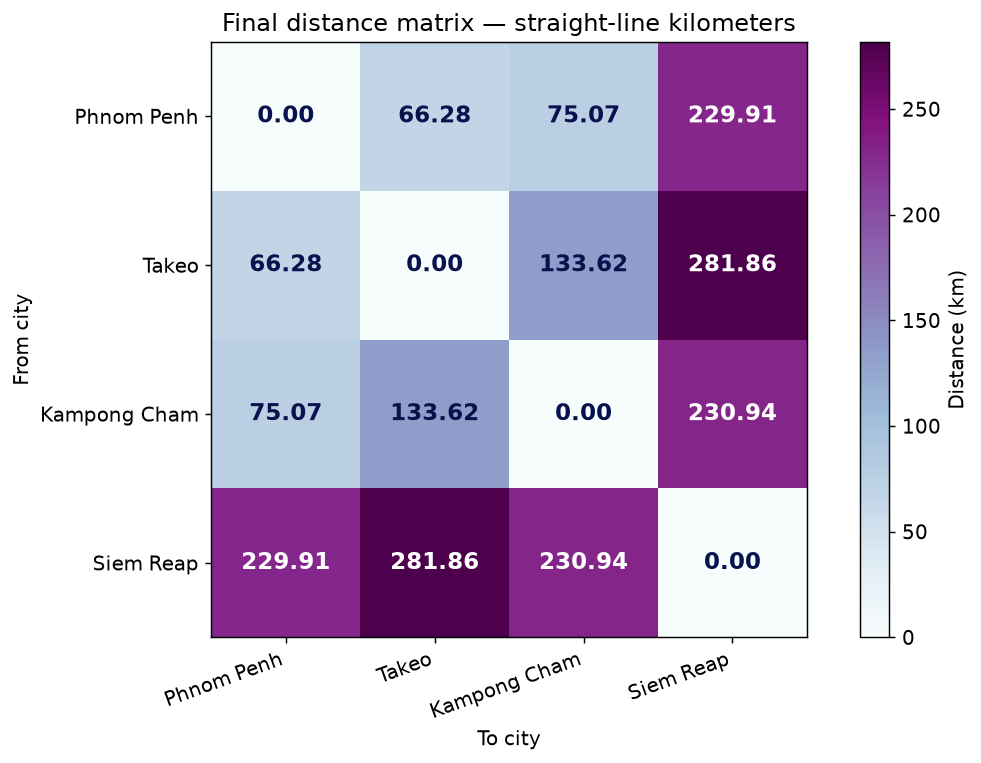

Numeric matrix passed to the TSP model:
[[  0.    66.28  75.07 229.91]
 [ 66.28   0.   133.62 281.86]
 [ 75.07 133.62   0.   230.94]
 [229.91 281.86 230.94   0.  ]]


In [17]:
matrix_data = build_straight_distance_matrix(locations)
distance_matrix = np.asarray(matrix_data['distances'], dtype=float)
assert distance_matrix.shape == (n, n)
assert np.allclose(distance_matrix, distance_matrix.T)
assert np.allclose(np.diag(distance_matrix), 0)

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(distance_matrix, cmap='BuPu', vmin=0)
ax.set_xticks(range(n), CITY_NAMES, rotation=20, ha='right')
ax.set_yticks(range(n), CITY_NAMES)
ax.set(xlabel='To city', ylabel='From city',
       title='Final distance matrix — straight-line kilometers')
for i in range(n):
    for j in range(n):
        color = 'white' if distance_matrix[i, j] > distance_matrix.max() * 0.6 else NAVY
        ax.text(j, i, f'{distance_matrix[i, j]:.2f}', ha='center', va='center',
                color=color, fontsize=13, fontweight='bold')
fig.colorbar(heatmap, ax=ax, label='Distance (km)')
plt.tight_layout()
plt.show()
print('Numeric matrix passed to the TSP model:')
print(np.array2string(distance_matrix, precision=2, suppress_small=True))


In [18]:
def route_names(tour):
    return ' → '.join(CITY_NAMES[i] for i in tour)

def tour_distance(tour):
    return float(sum(distance_matrix[a, b] for a, b in zip(tour, tour[1:])))



## 3. Encode the route (classical)
Phnom Penh is fixed outside the binary assignment. Three destinations × three positions need **9 qubits**. Set `RETURN_TO_START = False` for an open route. Normalized distances and a penalty of 4 keep the objective well scaled; reported distances remain kilometers.

In [19]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.translators import to_ising

RETURN_TO_START = True  # False: stop at the last destination.
m = n - 1
DISTANCE_SCALE = float(distance_matrix.max())
weights = distance_matrix / DISTANCE_SCALE
problem = QuadraticProgram('Route with fixed departure')
for city in range(m):
    for position in range(m):
        problem.binary_var(name=f'x_{city}_{position}')

# x_city_position now represents destination city+1, not Phnom Penh.
linear = {}
quadratic = {}
for city in range(m):
    linear[f'x_{city}_0'] = float(weights[0, city+1])
    if RETURN_TO_START:
        key = f'x_{city}_{m-1}'
        linear[key] = linear.get(key, 0.0) + float(weights[city+1, 0])
for position in range(m-1):
    for a in range(m):
        for b in range(m):
            if a != b:
                quadratic[(f'x_{a}_{position}', f'x_{b}_{position+1}')] = float(weights[a+1,b+1])
problem.minimize(linear=linear, quadratic=quadratic)
for city in range(m):
    problem.linear_constraint({f'x_{city}_{p}': 1 for p in range(m)}, '==', 1, f'city_{city}')
for position in range(m):
    problem.linear_constraint({f'x_{city}_{position}': 1 for city in range(m)}, '==', 1, f'position_{position}')

# A valid normalized route costs at most n (each leg <= 1).
# A non-permutation breaks at least two row/column constraints, costing >= 2*n.
PENALTY = float(n)
qubo = QuadraticProgramToQubo(penalty=PENALTY).convert(problem)
hamiltonian, offset = to_ising(qubo)
weighted_graph = nx.from_numpy_array(distance_matrix)
print('Return to Phnom Penh:', RETURN_TO_START)
print('Qubits:', hamiltonian.num_qubits, '| Pauli terms:', len(hamiltonian.paulis))
print('Distance scale (km):', round(DISTANCE_SCALE, 2), '| Penalty:', PENALTY)

Return to Phnom Penh: True
Qubits: 9 | Pauli terms: 39
Distance scale (km): 281.86 | Penalty: 4.0


## 4. Quantum processing
Start from the destinations in reverse input order. A swap mixer preserves valid assignments. CVaR focuses optimization on the lower-energy fraction of measurements.

### 4.1 Configure valid initialization and mixer
Use a four-qubit exchange that swaps two destinations between two positions. It preserves both one-city-per-position and one-position-per-city. CVaR uses the lowest-energy 75% of shots; depth is three layers.

In [20]:
from itertools import combinations
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Operator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.minimum_eigensolvers import QAOA

SHOTS = 1024
SEED = 42
P = 3
MAXITER = 250
CVAR_ALPHA = 1
backend = AerSimulator(max_parallel_threads=4)
pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
sampler = SamplerV2(default_shots=SHOTS, seed=SEED,
    options={'backend_options': {'max_parallel_threads': 4}})

# A deterministic feasible starting route; no shortest-route calculation.
initial_state = QuantumCircuit(m*m)
for position in range(m):
    initial_state.x((m-1-position)*m+position)

# Local basis exchange |1001> <-> |0110> on four assignment qubits.
exchange_matrix = np.zeros((16,16), dtype=complex)
exchange_matrix[9,6] = exchange_matrix[6,9] = 1
exchange_operator = SparsePauliOp.from_operator(Operator(exchange_matrix))
mixer = QuantumCircuit(m*m)
mix_beta = Parameter('mix_beta')
for a,b in combinations(range(m),2):
    for p,q in combinations(range(m),2):
        qubits = [a*m+p, a*m+q, b*m+p, b*m+q]
        mixer.append(PauliEvolutionGate(exchange_operator,time=mix_beta), qubits)

# Qiskit parameter order: all betas, followed by all gammas.
initial_angles = np.r_[np.full(P,0.4), np.full(P,1.0)]
print(f'{m*m} qubits | p={P} | CVaR alpha={CVAR_ALPHA} | shots={SHOTS}')
print('Initial destination order:', ' → '.join(reversed(CITY_NAMES[1:])))

9 qubits | p=3 | CVaR alpha=1 | shots=1024
Initial destination order: Siem Reap → Kampong Cham → Takeo


### 4.2 Optimize angles using CVaR
COBYLA minimizes the sampled lower-tail energy. A lower CVaR value is better, but it does not guarantee that the most frequent route is optimal.

Optimized parameters: [-0.47267658  0.92712552  0.72486024  0.9202416   0.91494974  1.1788021 ]
Objective evaluations: 49


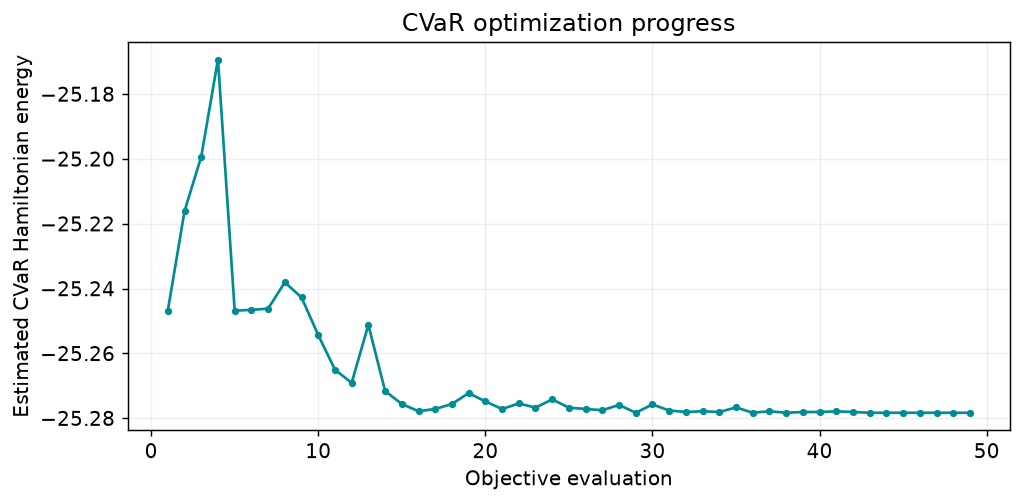

In [21]:
optimization_log = []
def record_evaluation(evaluation, parameters, mean, metadata):
    optimization_log.append((int(evaluation), float(np.real(mean))))

qaoa = QAOA(sampler=sampler, optimizer=COBYLA(maxiter=MAXITER, tol=1e-4),
    reps=P, initial_state=initial_state, mixer=mixer, aggregation=CVAR_ALPHA,
    pass_manager=pass_manager, initial_point=initial_angles, callback=record_evaluation)
optimization_started = perf_counter()
qaoa_result = qaoa.compute_minimum_eigenvalue(hamiltonian)
qaoa_optimization_seconds = perf_counter() - optimization_started
print('Optimized parameters:', qaoa_result.optimal_point)
print('Objective evaluations:', len(optimization_log))
evaluations, energies = zip(*optimization_log)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(evaluations, energies, 'o-', color=TEAL, markersize=3)
ax.set(xlabel='Objective evaluation', ylabel='Estimated CVaR Hamiltonian energy', title='CVaR optimization progress')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

### 4.3 Final measurement
Run the optimized circuit for 1,024 shots. Every histogram bar is an actual measured count.

In [22]:
sampling_started = perf_counter()
circuit = qaoa.ansatz.remove_final_measurements(inplace=False)
circuit = circuit.assign_parameters(qaoa_result.optimal_point)
circuit.measure_all()
compiled = transpile(circuit, backend, seed_transpiler=SEED)
counts = backend.run(compiled, shots=SHOTS, seed_simulator=SEED).result().get_counts()
qaoa_sampling_seconds = perf_counter() - sampling_started
assert sum(counts.values()) == SHOTS
print('Final shots:', sum(counts.values()), '| Unique bitstrings:', len(counts))

Final shots: 1024 | Unique bitstrings: 6


### Optimized QAOA circuit in the paper's notation

- **Initialization.** The three \(X\) gates prepare one valid tour in the one-hot encoding.
- **\(U_{\mathrm{P}}(\gamma_\ell)\).** The phase separator applies the TSP cost Hamiltonian in layer \(\ell\).
- **\(U_{\mathrm{M}}(\beta_\ell)\).** The mixer block groups the four-qubit partial swaps applied in that layer. A partial swap couples \(|1001\rangle\) and \(|0110\rangle\), which exchanges two cities between two tour positions.

The three pairs follow the alternating-operator structure in [Hadfield et al., Sections 3 and 5.1](https://www.mdpi.com/1999-4893/12/2/34). Our mixer applies the partial swaps sequentially across all pairs of destination positions. The drawing groups these gates into blocks while retaining their order. Qiskit constructs the alternating circuit from our cost Hamiltonian, starting tour, and custom mixer.

[Barkoutsos et al.](https://quantum-journal.org/papers/q-2020-04-20-256/) supplies the CVaR objective used in the classical angle-tuning loop. Rendering the image uses Qiskit's IBM Quantum style and requires Matplotlib and pylatexenc.

If another kernel reports that pylatexenc is missing, run `%pip install pylatexenc` in a notebook cell, then restart the kernel and run all cells.

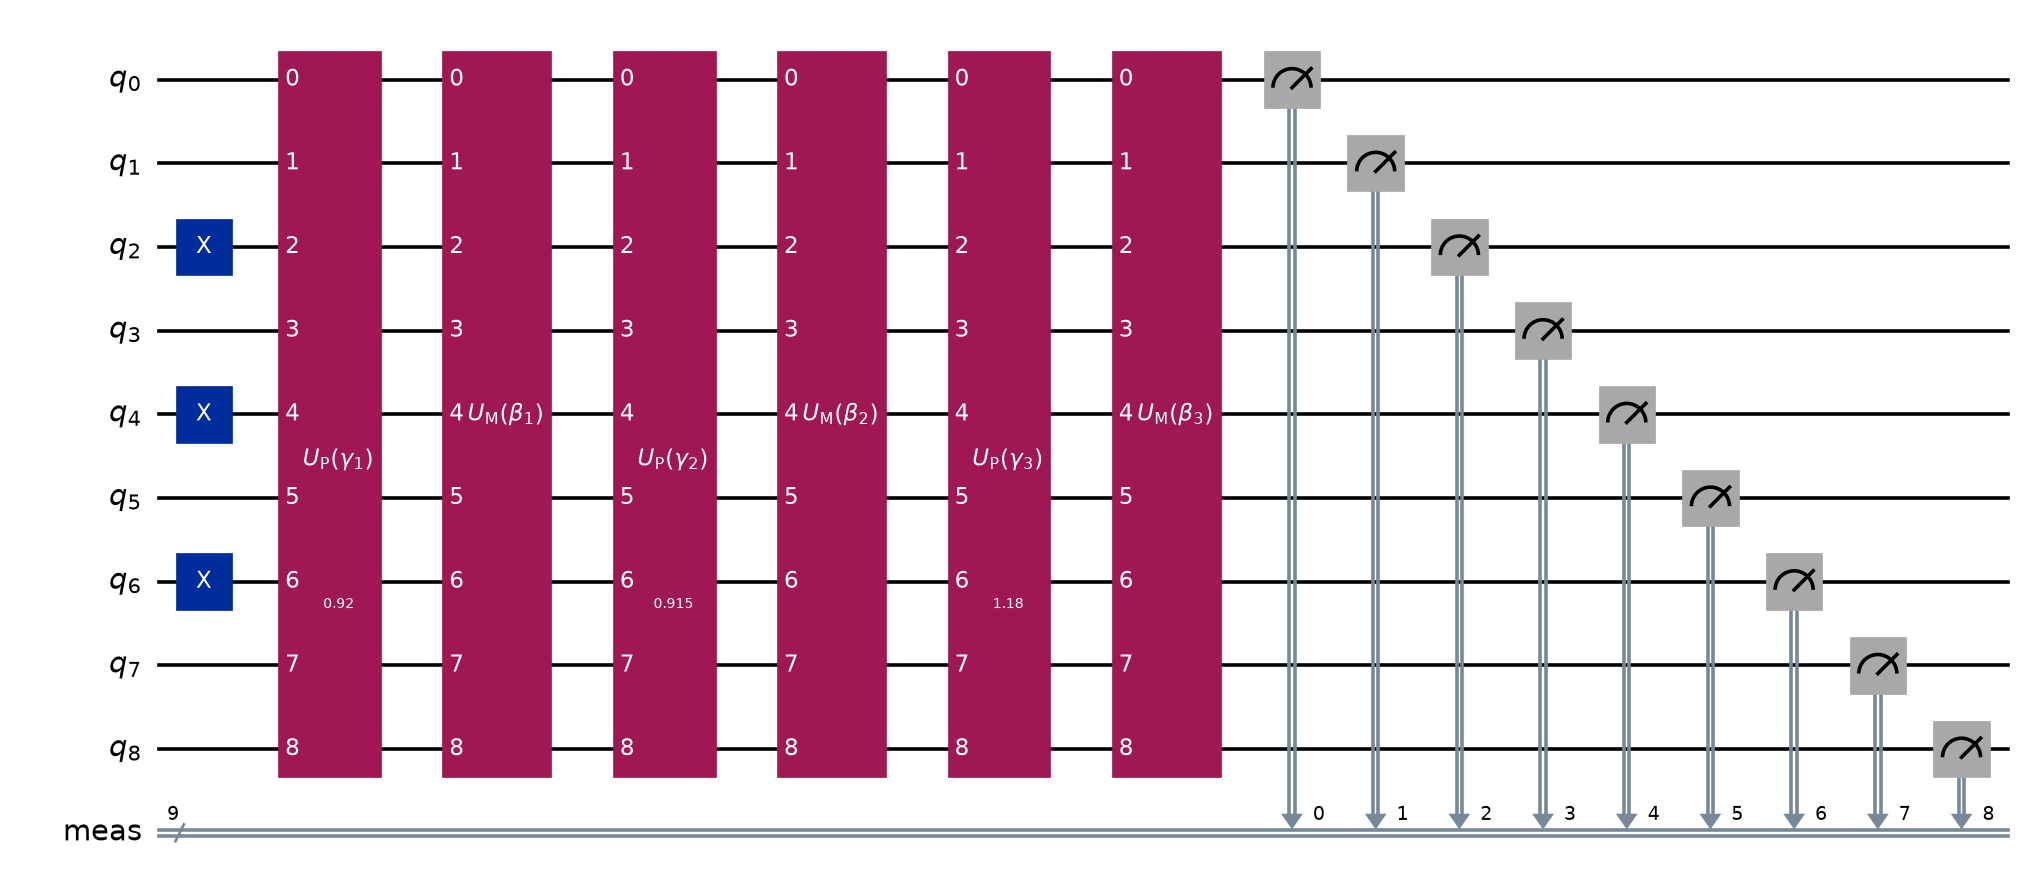

Aer circuit depth: 604
Aer gate counts: {'cx': 360, 'h': 162, 'ry': 108, 'rzz': 90, 'u3': 64, 'sdg': 40, 'u2': 38, 'rx': 36, 'rz': 24, 's': 15, 'rxx': 11, 'measure': 9, 'crx': 5, 'cry': 4, 'rzx': 3, 'ryy': 2, 'cp': 1, 'crz': 1, 'barrier': 1}


In [23]:
from IPython.display import display
from itertools import groupby

logical_circuit = circuit.decompose(reps=1)
diagram_circuit = logical_circuit.copy_empty_like()
layer = 0

def is_mixer_swap(instruction):
    gate = instruction.operation
    return isinstance(gate, PauliEvolutionGate) and gate.num_qubits < circuit.num_qubits

for swaps, instructions in groupby(logical_circuit.data, key=is_mixer_swap):
    if swaps:
        mixer_block = QuantumCircuit(circuit.num_qubits, name='Mixer')
        for instruction in instructions:
            wires = [logical_circuit.find_bit(qubit).index for qubit in instruction.qubits]
            mixer_block.append(instruction.operation, wires)
        mixer_label = rf'$U_{{\mathrm{{M}}}}(\beta_{{{layer}}})$'
        diagram_circuit.append(mixer_block.to_gate(label=mixer_label), diagram_circuit.qubits)
    else:
        for instruction in instructions:
            gate = instruction.operation
            if isinstance(gate, PauliEvolutionGate):
                layer += 1
                gate = gate.to_mutable()
                gate.label = rf'$U_{{\mathrm{{P}}}}(\gamma_{{{layer}}})$'
            diagram_circuit.append(gate, instruction.qubits, instruction.clbits)

display(diagram_circuit.draw(output='mpl', style='iqp', fold=-1, plot_barriers=False))
print(f'Aer circuit depth: {compiled.depth()}')
print('Aer gate counts:', dict(compiled.count_ops()))


### 4.4 Validate and show measured frequencies (classical)
Decode assignments and check feasibility. Count every final shot as measured. No invalid-bitstring repair, optimizer-best fallback, or shortest-candidate selection is used.

Valid final shots: 1024/1024 (100.00%)
Unique valid measured assignments: 6


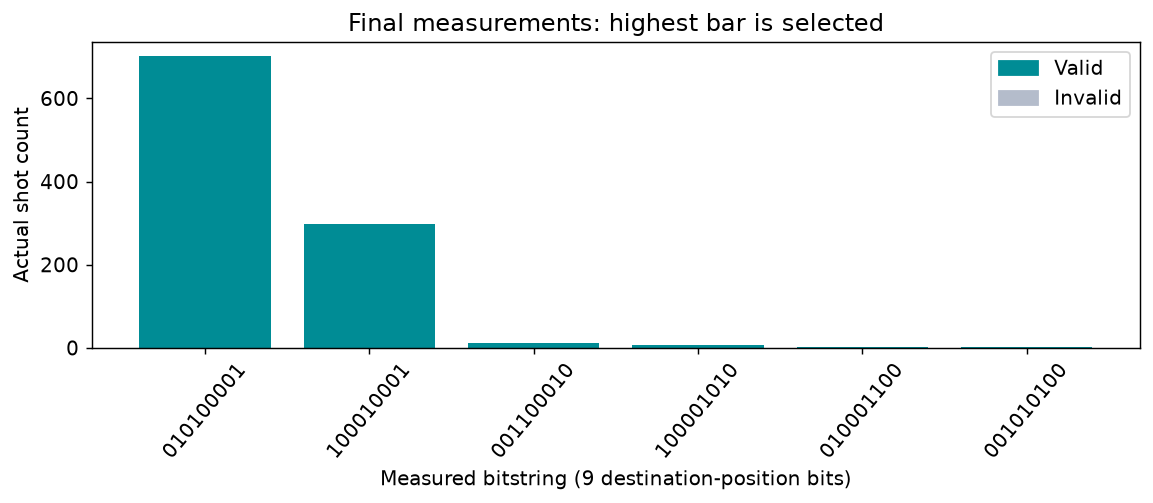

In [24]:
def decode_tour(bitstring):
    assignment = np.array([int(bit) for bit in bitstring[::-1]]).reshape(m,m)
    if not (np.all(assignment.sum(axis=0)==1) and np.all(assignment.sum(axis=1)==1)):
        return None
    destinations = [int(np.argmax(assignment[:,p]))+1 for p in range(m)]
    return [0, *destinations] + ([0] if RETURN_TO_START else [])

valid_shots = sum(count for bits,count in counts.items() if decode_tour(bits) is not None)
print(f'Valid final shots: {valid_shots}/{SHOTS} ({100*valid_shots/SHOTS:.2f}%)')
print('Unique valid measured assignments:',sum(decode_tour(bits) is not None for bits in counts))
from matplotlib.patches import Patch
top_counts = sorted(counts.items(),key=lambda item:item[1],reverse=True)[:10]
fig,ax = plt.subplots(figsize=(9,4))
ax.bar([bits for bits,count in top_counts],[count for bits,count in top_counts],
    color=[TEAL if decode_tour(bits) is not None else '#b4bccb' for bits,count in top_counts])
ax.set(xlabel='Measured bitstring (9 destination-position bits)',ylabel='Actual shot count',
    title='Final measurements: highest bar is selected')
ax.tick_params(axis='x',rotation=50)
ax.legend(handles=[Patch(color=TEAL,label='Valid'),Patch(color='#b4bccb',label='Invalid')])
plt.tight_layout()
plt.show()

## 5. Decode the highest bar and display

Select the most frequently measured bitstring, check feasibility, and compute the resulting route length. The Held–Karp comparison follows after selection.

Selection: highest measured count (no route-length comparison)
Selected route: Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh
Distance: 654.16 km | Final count: 701
Measured 9-bit assignment: 010100001


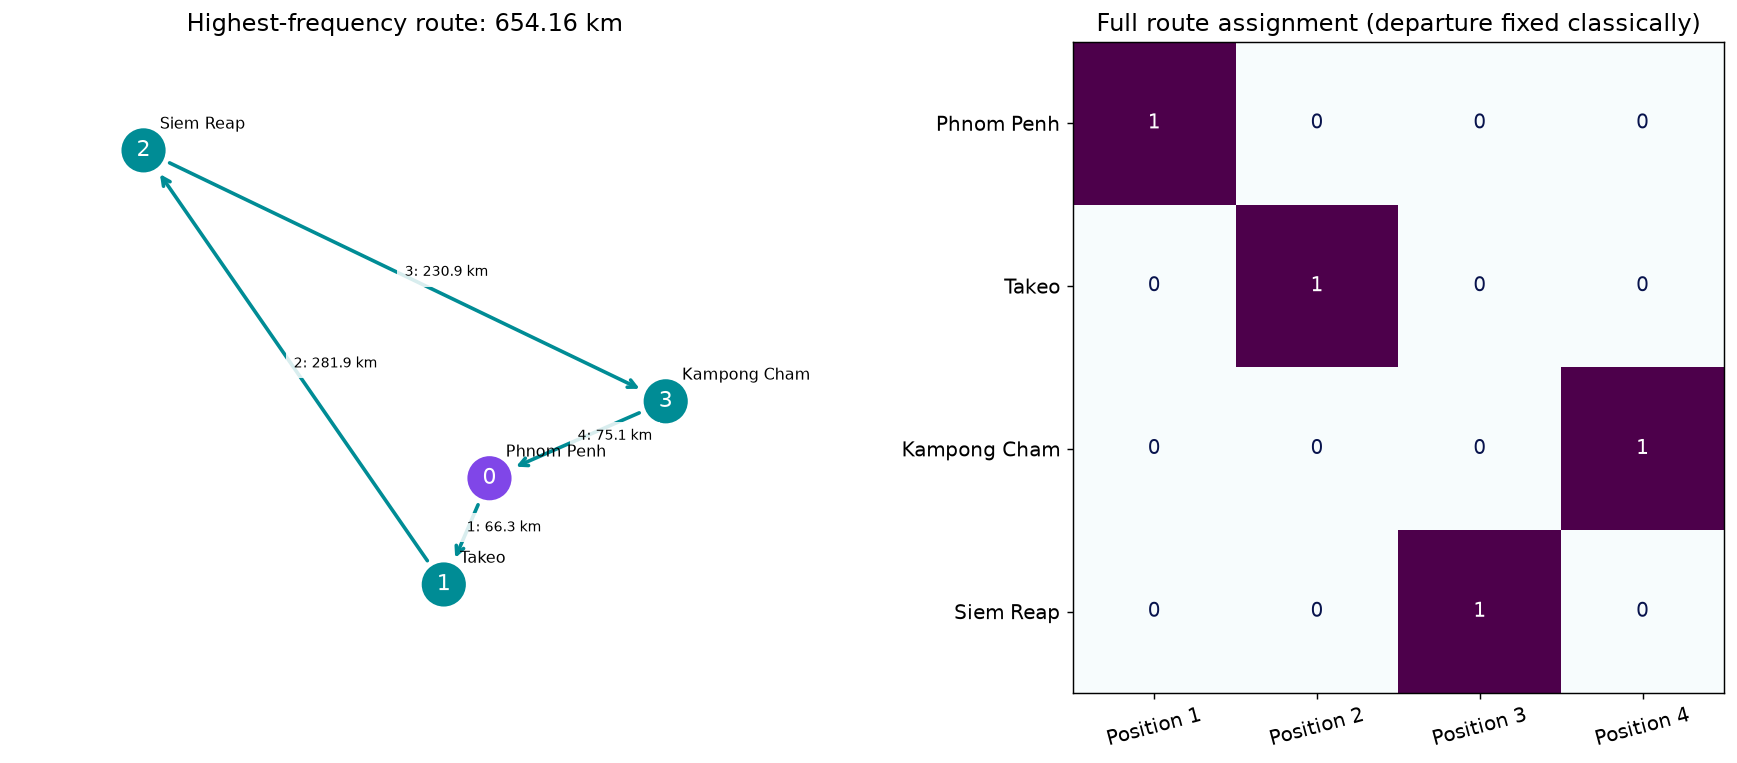

In [25]:
selection_started = perf_counter()
selected = None
winner_bits = max(counts,key=counts.get)
winner_tour = decode_tour(winner_bits)
qaoa_selection_seconds = perf_counter() - selection_started
if winner_tour is not None:
    selected = {'tour':winner_tour,'bitstring':winner_bits,'count':counts[winner_bits]}
    selected_tour = selected['tour']
    selected_distance = tour_distance(selected_tour)
    print('Selection: highest measured count (no route-length comparison)')
    print('Selected route:',route_names(selected_tour))
    print(f'Distance: {selected_distance:.2f} km | Final count: {selected["count"]}')
    print('Measured 9-bit assignment:',selected['bitstring'])
    assignment = np.zeros((n,n),dtype=int)
    cities = selected_tour[:-1] if RETURN_TO_START else selected_tour
    for position,city in enumerate(cities):
        assignment[city,position]=1
    assert np.all(assignment.sum(0)==1) and np.all(assignment.sum(1)==1)
    fig,(ax,grid_ax)=plt.subplots(1,2,figsize=(14,6))
    nx.draw_networkx_nodes(weighted_graph,positions,ax=ax,node_color=node_colors,node_size=550)
    # Node numbers show visit order, while city indices remain unchanged internally.
    visit_labels = {city: str(position) for position,city in enumerate(cities)}
    nx.draw_networkx_labels(weighted_graph,positions,labels=visit_labels,ax=ax,font_color='white')
    for step,(a,b) in enumerate(zip(selected_tour,selected_tour[1:]),1):
        ax.annotate('',xy=positions[b],xytext=positions[a],
            arrowprops={'arrowstyle':'->','color':TEAL,'lw':2,'shrinkA':16,'shrinkB':16})
        midpoint=(np.array(positions[a])+np.array(positions[b]))/2
        ax.text(*midpoint,f'{step}: {distance_matrix[a,b]:.1f} km',fontsize=8,
            bbox={'facecolor':'white','edgecolor':'none','alpha':.85})
    for i,point in positions.items():
        ax.annotate(CITY_NAMES[i],point,xytext=(9,12),textcoords='offset points',fontsize=9)
    ax.margins(.25)
    ax.set_axis_off()
    ax.set_title(f'Highest-frequency route: {selected_distance:.2f} km')
    grid_ax.imshow(assignment,cmap='BuPu',vmin=0,vmax=1)
    grid_ax.set_xticks(range(n),[f'Position {p+1}' for p in range(n)],rotation=15)
    grid_ax.set_yticks(range(n),CITY_NAMES)
    grid_ax.set_title('Full route assignment (departure fixed classically)')
    for i in range(n):
        for p in range(n):
            grid_ax.text(p,i,str(assignment[i,p]),ha='center',va='center',
                color='white' if assignment[i,p] else NAVY)
    plt.tight_layout()
    plt.show()
else:
    print('The highest bar is invalid. Report failure; do not replace it with another route.')

## 6. Compare QAOA with CVaR and classical Held–Karp

| | QAOA with CVaR | Held–Karp |
| --- | --- | --- |
| How it searches | A permutation-swap circuit generates samples. COBYLA tunes the circuit angles using the lower-energy fraction of samples. | Dynamic programming stores the cheapest path for each visited subset and final stop. |
| How it picks a route | Selects the most frequently measured assignment. Quality can vary with circuit settings and sampling. | Reconstructs the minimum-distance route in $O(m^2 2^m)$ time for $m$ destinations. |

Both use the same departure, destinations and return setting. For an open route, Held–Karp uses a free final edge back to the depot internally, then drops that edge from the reported route. A zero gap means the two routes have the same distance. A round trip can have the same length in either direction.

**Timing scope.** Each time is the wall-clock duration of one local run. QAOA includes CVaR angle optimization, final circuit compilation and sampling in Aer, and decoding the selected assignment. Held–Karp includes the dynamic programming search and route reconstruction. Both timers exclude API calls, location lookup, distance matrix construction, imports, solver setup, QUBO encoding, and plotting.

In [26]:
from IPython.display import Markdown, display
from app.classical.held_karp import held_karp_tour

classical_weights = distance_matrix.copy()
if not RETURN_TO_START:
    classical_weights[:, 0] = 0.0
classical_input = classical_weights.tolist()
classical_started = perf_counter()
classical_tour = held_karp_tour(classical_input)
classical_compute_seconds = perf_counter() - classical_started
if not RETURN_TO_START:
    classical_tour = classical_tour[:-1]
classical_distance = tour_distance(classical_tour)

quantum_route_label = 'Highest-frequency assignment was infeasible'
quantum_distance_label = 'Unavailable'
gap_label = 'Unavailable'
shots_label = 'Unavailable'
if selected is not None:
    quantum_distance = tour_distance(selected['tour'])
    gap_km = quantum_distance - classical_distance
    if np.isclose(gap_km, 0.0, rtol=0.0, atol=1e-8):
        gap_km = 0.0
    quantum_route_label = route_names(selected['tour'])
    quantum_distance_label = f'{quantum_distance:.2f} km'
    gap_label = f'{gap_km:.2f} km'
    if classical_distance > 0:
        gap_label += f' ({100 * gap_km / classical_distance:.2f}%)'
    shots_label = f"{selected['count']:,} / {SHOTS:,} ({100 * selected['count'] / SHOTS:.2f}%)"

qaoa_compute_seconds = qaoa_optimization_seconds + qaoa_sampling_seconds + qaoa_selection_seconds

display(Markdown('\n'.join([
    '| Result | QAOA with CVaR | Held–Karp |',
    '| --- | --- | --- |',
    f'| Selected route | {quantum_route_label} | {route_names(classical_tour)} |',
    f'| Total distance | {quantum_distance_label} | {classical_distance:.2f} km |',
    f'| Gap to exact minimum | {gap_label} | Exact minimum |',
    f'| Shots for the selected assignment | {shots_label} | — |',
    f'| **Raw compute time** | **{qaoa_compute_seconds * 1000:,.3f} ms** | **{classical_compute_seconds * 1000:,.3f} ms** |',
    f'| CVaR angle optimization | {qaoa_optimization_seconds * 1000:,.3f} ms | — |',
    f'| Final compilation and sampling | {qaoa_sampling_seconds * 1000:,.3f} ms | — |',
    f'| Select and decode assignment | {qaoa_selection_seconds * 1000:,.3f} ms | — |',
])))

| Result | QAOA with CVaR | Held–Karp |
| --- | --- | --- |
| Selected route | Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh | Phnom Penh → Kampong Cham → Siem Reap → Takeo → Phnom Penh |
| Total distance | 654.16 km | 654.16 km |
| Gap to exact minimum | 0.00 km (0.00%) | Exact minimum |
| Shots for the selected assignment | 701 / 1,024 (68.46%) | — |
| **Raw compute time** | **625.986 ms** | **0.029 ms** |
| CVaR angle optimization | 550.672 ms | — |
| Final compilation and sampling | 75.227 ms | — |
| Select and decode assignment | 0.087 ms | — |

## Interpretation

A zero gap shows that the highest-frequency QAOA assignment reached the exact minimum for this instance. The percentage of optimal shots in the validation cell counts every minimum-distance assignment, including tours that differ only in direction.

This four-city example uses a noiseless Aer simulator and compares route quality for a single instance. Broader performance claims would require more instances, sizes, and seeds. See the project's CVaR trials and validation script for the seed experiments.